In [1]:
## Calculate log return 
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ticker = "PLTR"

stock = yf.download(
    ticker,
    start="2021-10-01",
    end="2026-10-09",
    auto_adjust=False,
    progress=False
)


prices = stock["Adj Close"].copy()
log_return = np.log(prices).diff().dropna()
print("Observations: ", len(log_return))
print(log_return.head())

split_index = int(len(log_return)*0.8)
print(split_index)

## 80% Calibration return / 20% validation return
calibration_return = log_return.iloc[:split_index]
validation_return = log_return.iloc[split_index:]
histrocial_volatility_benchmark = np.std(calibration_return, ddof=1)

## Historical return - GBM method constant volatility 
annualized_histrocial_volatility_benchmark = histrocial_volatility_benchmark*np.sqrt(252)
print(histrocial_volatility_benchmark)
print(annualized_histrocial_volatility_benchmark)
print(calibration_return.shape)
print(validation_return.shape)

Observations:  1259
Ticker          PLTR
Date                
2021-10-04 -0.048852
2021-10-05  0.001725
2021-10-06  0.015816
2021-10-07  0.006341
2021-10-08 -0.009740
1007
0.042385935836716064
0.6728558718641469
(1007, 1)
(252, 1)


## EWMA Volatility Estimation

EWMA recursively estimates conditional variance using past returns.
The decay factor lambda controls how quickly the model responds to new information.

0.9 (1007,) 0.5045842405654614
0.94 (1007,) 0.47405396643582515
0.97 (1007,) 0.49216325079276446


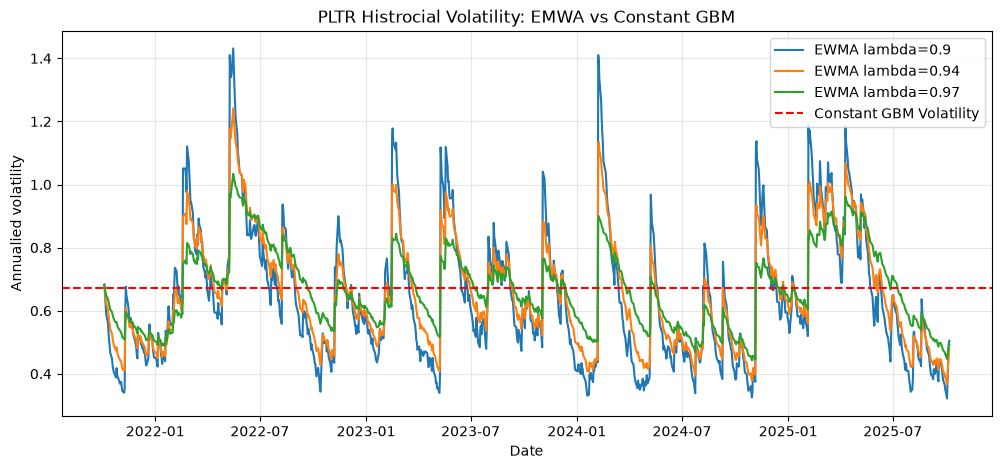

In [2]:
lambdas = [0.90, 0.94, 0.97]
ewma_result ={}

returns = calibration_return.to_numpy().flatten()
initial_variance = np.var(returns, ddof=1)

## create a same legnth array to contain ewma variance
for lam in lambdas:
    ewma_variance = np.zeros(len(returns))
    ewma_variance[0] = initial_variance

    for t in range(1, len(returns)):
        ewma_variance[t] = lam*ewma_variance[t-1] + (1-lam)*returns[t-1]**2

    ## Annualize volatility
    ewma_result[lam] = np.sqrt(252*ewma_variance)

for lam, vol in ewma_result.items():
    print(lam, vol.shape, vol[-1])


## Visualization
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))

for lam, vol in ewma_result.items():
    plt.plot(
        calibration_return.index,
        vol,
        label = f"EWMA lambda={lam}"
    )

## Add Constant GBM as benchmark
plt.axhline(
    y = annualized_histrocial_volatility_benchmark,
    color = "red",
    linestyle = "--",
    label = "Constant GBM Volatility"
)

plt.title("PLTR Histrocial Volatility: EMWA vs Constant GBM")
plt.xlabel("Date")
plt.ylabel("Annualied volatility")
plt.legend()
plt.grid(alpha =0.3)
plt.show()

In [3]:
## Calculate MSE for three lambdas
burn_in = 30
ewma_mse = {}

for lam, vol in ewma_result.items():
    daily_variance = vol**2/252
    square_error =(
        daily_variance[burn_in:] - returns[burn_in:]**2
    )**2
    ewma_mse[lam] = np.mean(square_error)
print(ewma_mse)

## Chose lambdas with the lowest MSE
best_lambda = min(ewma_mse, key=ewma_mse.get)
print("Best lambda: ", best_lambda)
print("Minimum MSE: ", ewma_mse[best_lambda])

{0.9: np.float64(2.572232757044945e-05), 0.94: np.float64(2.5308077610561216e-05), 0.97: np.float64(2.5025628609694488e-05)}
Best lambda:  0.97
Minimum MSE:  2.5025628609694488e-05


### EWMA Decay Parameter Selection

Three EWMA decay parameters lambda=0.90, 0.94, 0.97 were evaluated using the Mean Squared Error (MSE) between one-day-ahead conditional variance estimates and realized squared daily log returns.

The first 30 observations were excluded as a burn-in period to reduce the influence of variance initialization.

The results indicate that lambda=0.97 achieves the lowest MSE (2.50256 × 10⁻⁵)**, compared with 2.53081 × 10⁻⁵ for lambda=0.94 and 2.57223 × 10⁻⁵ for lambda=0.90.

A higher decay parameter places greater weight on historical variance and produces smoother volatility estimates with slower responses to new shocks.

Therefore, **lambda=0.97 was selected as the preferred EWMA parameter** based on the in-sample MSE criterion. Further out-of-sample validation would be required to assess its forecasting robustness.

In [4]:
## Validation forecast
validation_returns = validation_return.to_numpy().flatten()
validation_emwa_variance = np.zeros(len(validation_returns))

last_cal_variance = ewma_result[best_lambda][-1]**2/252
validation_emwa_variance[0] = (
    best_lambda*last_cal_variance+
    (1-best_lambda)*returns[-1]**2
)

for t in range(1, len(validation_returns)):
    validation_emwa_variance[t] = best_lambda*validation_emwa_variance[t-1] + (1-best_lambda)*validation_returns[t-1]**2

## EWMA Validation MSE
ewma_validation_mse = np.mean(
    (validation_emwa_variance - validation_returns**2)**2
)

## Constant GBM Validation MSE
gbm_daily_variance = histrocial_volatility_benchmark**2
gbm_validation_mse = np.mean(
    (gbm_daily_variance - validation_returns**2)**2
)

print("EWMA Validation MSE:", ewma_validation_mse)
print("GBM Validation MSE:", gbm_validation_mse)

# Compare the two models
if (ewma_validation_mse<gbm_validation_mse):
    print("EWMA performs better")
else:
    print("Constant GBM performs better")

EWMA Validation MSE: 2.07599690299961e-05
GBM Validation MSE: 2.0572226424633666e-05
Constant GBM performs better


## GARCH(1,1) — Conditional Volatility Modeling

### Objective

Estimate the time-varying conditional volatility of PLTR stock returns using a GARCH(1,1) model, and evaluate its out-of-sample forecasting performance against Constant-Volatility GBM and EWMA.

### Estimation and Validation

1. Use the first 80% of historical log returns as the calibration sample.
2. Estimate GARCH(1,1) parameters using Maximum Likelihood Estimation (MLE).
3. Keep estimated parameters fixed during the validation period.
4. Update one-step-ahead conditional variance forecasts using previously observed returns.
5. Compare forecasting performance against Constant GBM and EWMA using out-of-sample MSE.

### Expected Outputs

- Estimated GARCH(1,1) parameters.
- Annualized conditional volatility time series.
- Comparison of GARCH, EWMA, and Constant GBM volatility estimates.
- Out-of-sample validation MSE.
- Discussion of volatility clustering, persistence, and mean reversion.

In [ ]:
from arch import arch_model
garch_returns = calibration_return.to_numpy().flatten()*100

model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_fit = model.fit(disp="off")
print(garch_fit.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2875.03
Distribution:                  Normal   AIC:                           5758.05
Method:            Maximum Likelihood   BIC:                           5777.71
                                        No. Observations:                 1007
Date:                Wed, Oct 14 2026   Df Residuals:                     1006
Time:                        13:34:55   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.1963      0.138      1.427      0.154 [-7.33

(1007,)
[2.94948896 3.36928601 3.47880412 3.57255599 3.63033891]


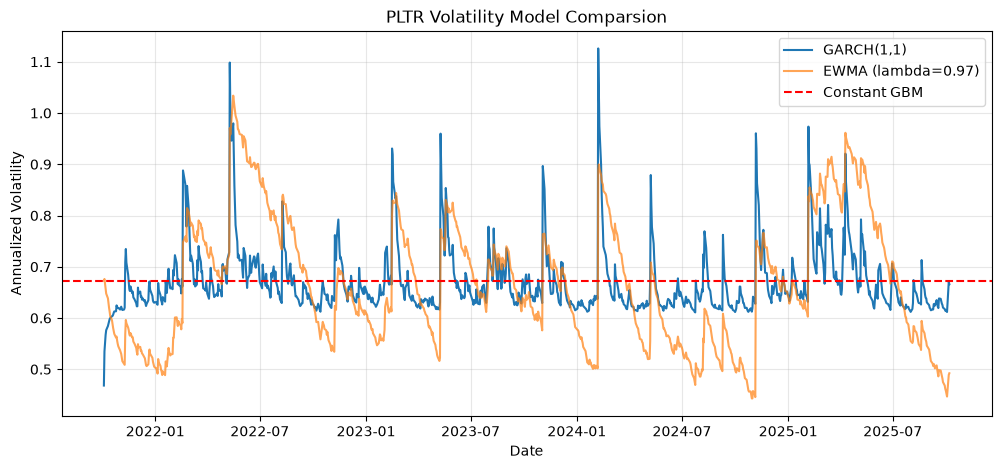

In [6]:
garch_vol = garch_fit.conditional_volatility
print(garch_vol.shape)
print(garch_vol[:5])
garch_annula_vol = garch_vol*np.sqrt(252)/100

## Visualization
plt.figure(figsize=(12,5))
plt.plot(
    calibration_return.index,
    garch_annula_vol,
    label = "GARCH(1,1)"
)
plt.plot(
    calibration_return.index,
    ewma_result[best_lambda],
    label = f"EWMA (lambda={best_lambda})",
    alpha =0.7
)
plt.axhline(
    annualized_histrocial_volatility_benchmark,
    color ="red",
    linestyle = "--",
    label = "Constant GBM"
)

plt.title("PLTR Volatility Model Comparsion")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In [7]:
## GARCH Parameter Diagnostics
param = garch_fit.params

mu = param["mu"]
omega = param["omega"]
alpha = param["alpha[1]"]
beta = param["beta[1]"]
print(mu, omega,alpha, beta)

persistence = alpha+beta
unconditional_variance = omega/(1-persistence)
unconditional_volatility_annual = np.sqrt(unconditional_variance)/100*np.sqrt(252)

print("Persistence:", persistence)
print("Unconditional Variance:", unconditional_variance)
print("Annualized Volatility:", unconditional_volatility_annual)

0.19626036363177338 3.5101812126353376 0.04870716302121454 0.756853643016407
Persistence: 0.8055608060376216
Unconditional Variance: 18.052847993776986
Annualized Volatility: 0.6744863004117875


In [8]:
## GARCH Validation forecast

garch_validation_returns = validation_returns*100

garch_validation_variance = np.zeros(
    len(garch_validation_returns)
)

## Forecast for Validation date 1
garch_validation_variance[0] = (
    omega
    +alpha*(returns[-1]*100-mu)**2
    +beta*(garch_vol[-1])**2
)
# Forecast for Validation Day 2 onward
for t in range(1, len(garch_validation_returns)):
    garch_validation_variance[t] =(
        omega
        +alpha*(garch_validation_returns[t-1]-mu)**2
        +beta*garch_validation_variance[t-1]
    )

garch_validation_variance_decimal = (
    garch_validation_variance / 10000
)

garch_validation_mse = np.mean(
    (garch_validation_variance_decimal - validation_returns**2)**2
)

print("GARCH Validation MSE:", garch_validation_mse)

GARCH Validation MSE: 2.0526393603655128e-05


In [9]:
## Compare three models 
model_mse = {
    "Constant GBM": gbm_validation_mse,
    "EWMA" : ewma_validation_mse,
    "GARCH(1,1): ": garch_validation_mse
}
for model_name, mse in model_mse.items():
    print(model_name, mse)

best_model = min(model_mse, key=model_mse.get)
print("Best volatility forecast model:", best_model)

Constant GBM 2.0572226424633666e-05
EWMA 2.07599690299961e-05
GARCH(1,1):  2.0526393603655128e-05
Best volatility forecast model: GARCH(1,1): 


## Volatility Response to Extreme Market Shocks

### Objective

Analyze how EWMA and GARCH(1,1) respond to extreme stock returns and compare their volatility persistence and mean-reversion behavior.

According to Question 1(b), we must:

1. Identify the five largest absolute daily log returns in the validation sample.
2. Examine the EWMA and GARCH conditional variance forecasts over the following ten trading days.
3. Compare the magnitude, speed, and persistence of volatility responses.
4. Explain the differences using the fitted model equations and parameters rather than relying solely on visual observations.

### Expected Deliverables

- A table identifying the five largest absolute validation returns and their dates.
- Five plots comparing EWMA and GARCH volatility responses over the following ten trading days.
- A quantitative comparison of the two models using their fitted parameters.
- A short discussion of volatility clustering, persistence, and mean reversion.

Date
2026-08-04    0.258162
2026-02-04   -0.123484
2026-08-07    0.098210
2026-05-29    0.088092
2025-11-10    0.084456
Name: PLTR, dtype: float64
Shock date:  2026-08-04 00:00:00


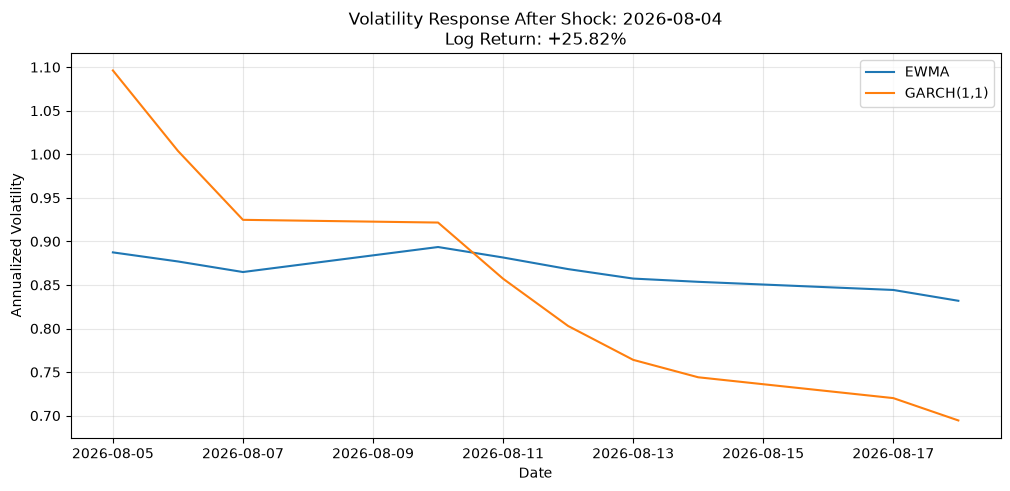

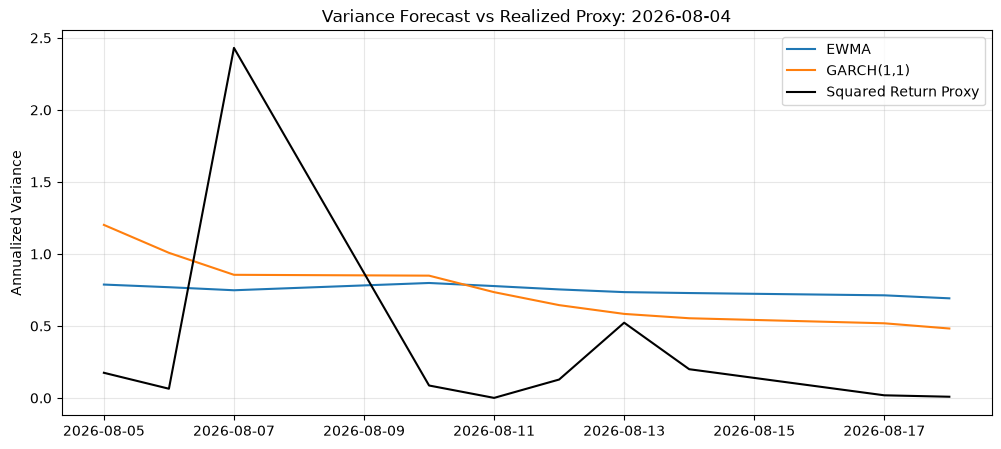

Shock date:  2026-02-04 00:00:00


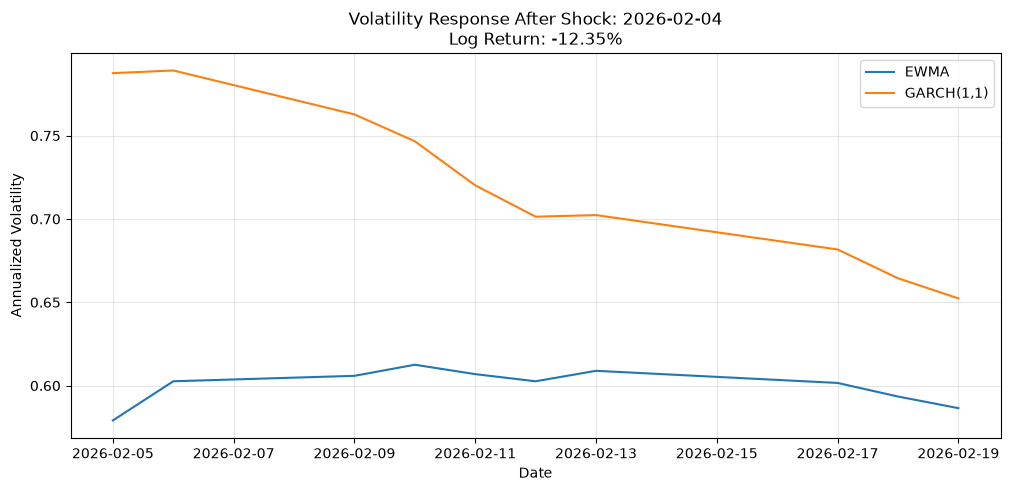

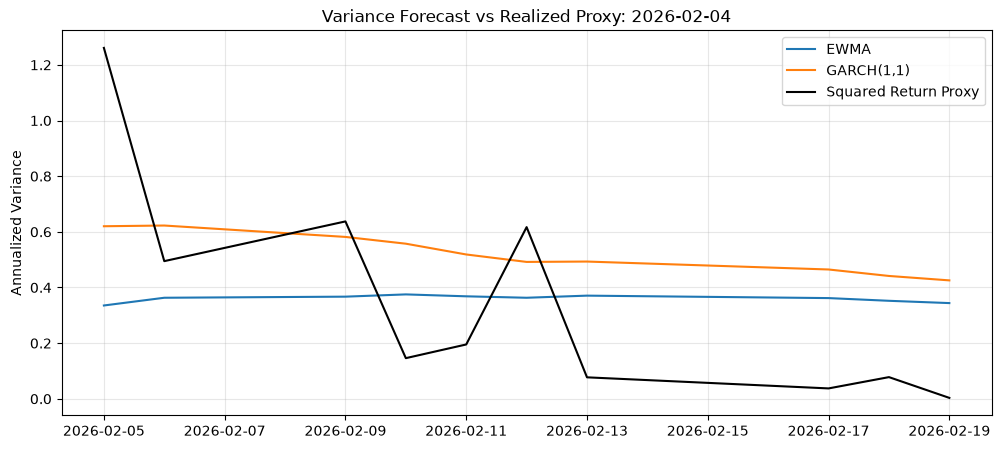

Shock date:  2026-08-07 00:00:00


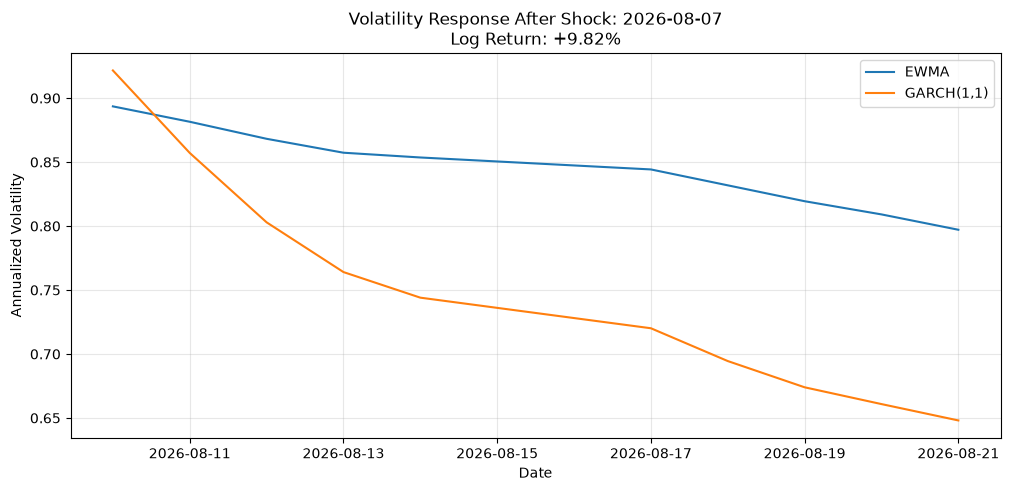

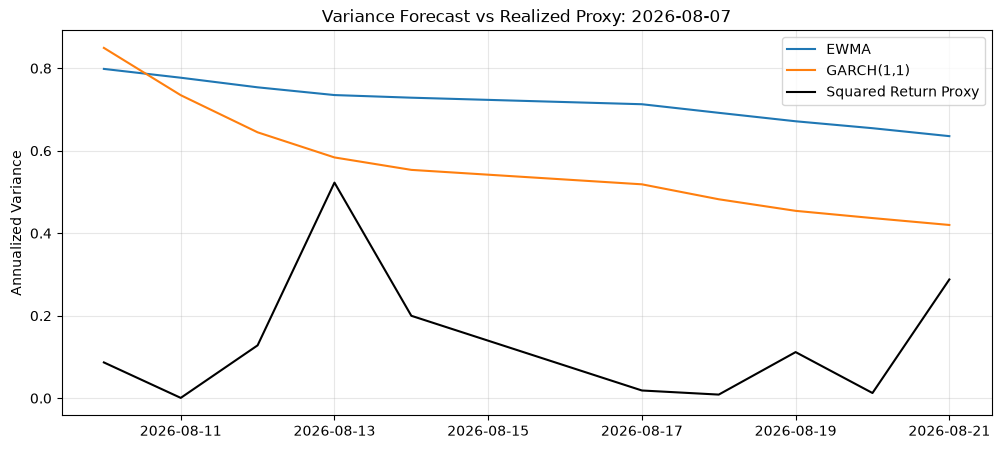

Shock date:  2026-05-29 00:00:00


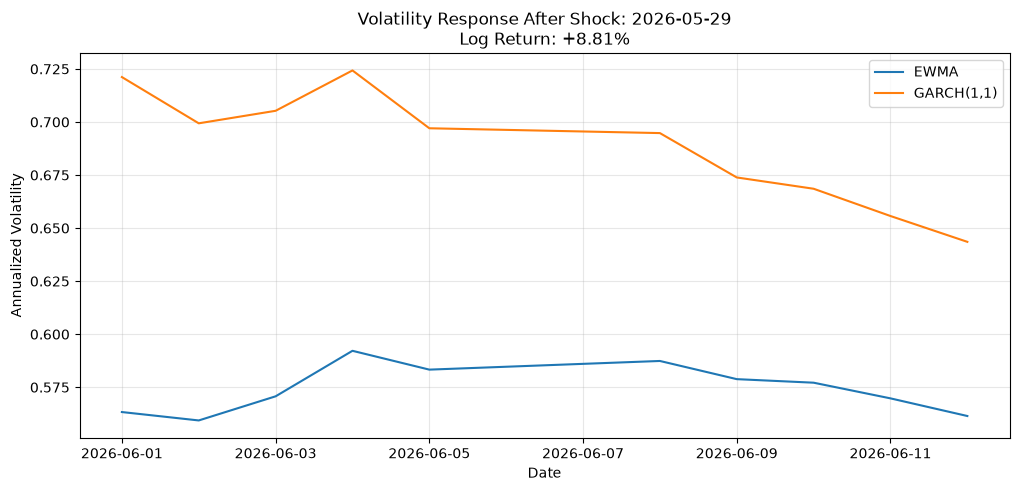

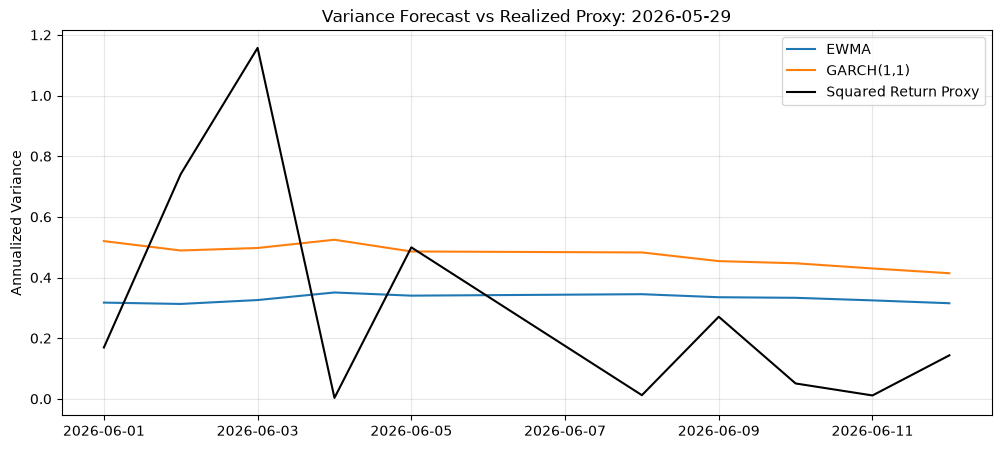

Shock date:  2025-11-10 00:00:00


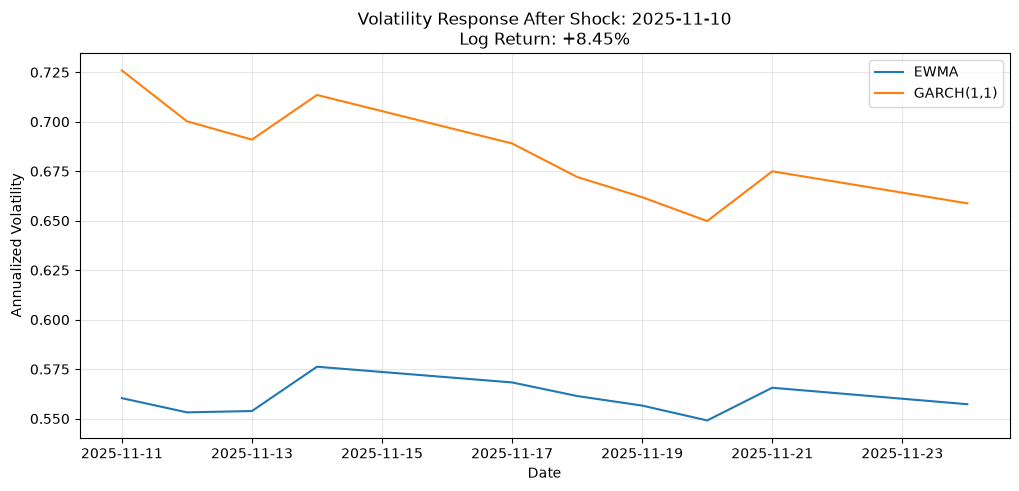

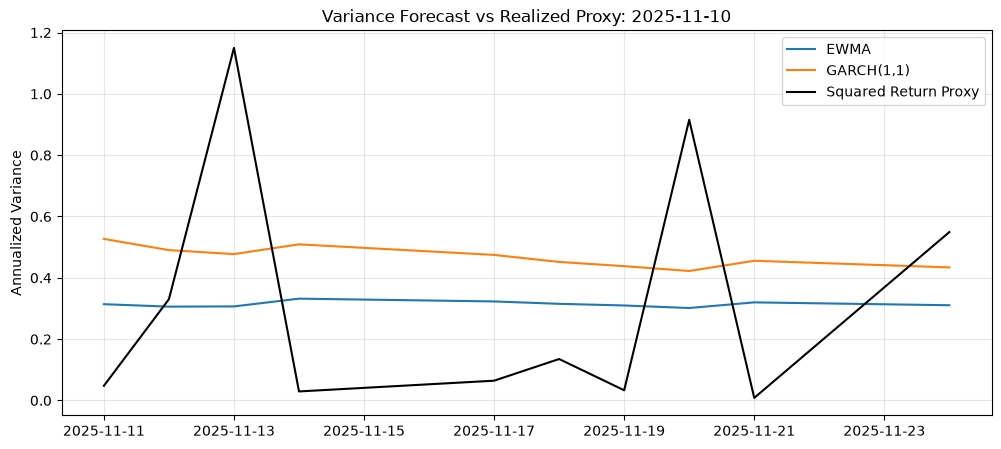

In [10]:
return_series = validation_return.iloc[:,0]
top5_abs_returns = return_series.abs().nlargest(5)
top5_original_returns = return_series.loc[top5_abs_returns.index]

print(top5_original_returns)

import matplotlib.pyplot as plt

for shock_date in top5_original_returns.index:
    shock_position = return_series.index.get_loc(shock_date)
    next_10_returns = return_series.iloc[shock_position+1:shock_position+11]

    print("Shock date: ", shock_date)

    next_10_ewma_variance = validation_emwa_variance[shock_position+1:shock_position+11]
    next_10_garch_variance = garch_validation_variance_decimal[
    shock_position+1:shock_position+11]
    shock_return = top5_original_returns.loc[shock_date]
    
    next_10_ewma_vol = np.sqrt(252*next_10_ewma_variance)
    next_10_garch_vol = np.sqrt(252*next_10_garch_variance)

    # Annualized realized variance proxy
    realized_variance_proxy = 252 * next_10_returns.to_numpy()**2

    # Annualized forecast variance
    ewma_variance_annual = 252 * next_10_ewma_variance
    garch_variance_annual = 252 * next_10_garch_variance

    next_10_dates = next_10_returns.index
    plt.figure(figsize=(12,5))

    plt.plot(
        next_10_dates,
        next_10_ewma_vol,
        label = "EWMA"
    )

    plt.plot(
        next_10_dates,
        next_10_garch_vol,
        label = "GARCH(1,1)"
    )    

    plt.title(f"Volatility Response After Shock: {shock_date.date()}\n"
              f"Log Return: {shock_return:+.2%}")
    plt.xlabel("Date")
    plt.ylabel("Annualized Volatility")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Picture of variance between proxy squared return, and EWMA & GARCH
    plt.figure(figsize=(12,5))
    plt.plot(next_10_dates, ewma_variance_annual,label = "EWMA")
    plt.plot(next_10_dates, garch_variance_annual, label = "GARCH(1,1)")
    plt.plot(next_10_dates, realized_variance_proxy, label="Squared Return Proxy", color="black")

    plt.ylabel("Annualized Variance")
    plt.title(f"Variance Forecast vs Realized Proxy: {shock_date.date()}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


### Shock Response Analysis: EWMA vs. GARCH(1,1)

The five largest absolute daily log returns in the validation sample were identified, and the subsequent ten trading days were examined to compare the responses of EWMA and GARCH(1,1) volatility forecasts.

**Model Dynamics**

The EWMA model follows:

sigma_{t+1}^2=lambda*sigma_t^2+(1-\lambda)r_t^2


EWMA assigns exponentially declining weights to past squared returns. It does not include an explicit long-run variance target.

The fitted GARCH(1,1) model follows:

sigma_{t+1}^2=omega+alpha*(retunr_t-mu)^2+beta*sigma_t^2

The estimated parameters are:

- Omega = 3.5102
- Alpha = 0.0487
- Beta = 0.7569
- Persistence = 0.8056

The fitted persistence is below one, indicating a mean-reverting conditional variance process under the standard GARCH assumptions. The estimated long-run annualized volatility is approximately 67.45%.

**Empirical Findings**

The largest shock occurred on August 4, 2026, with a daily log return of approximately +25.82%. Both models initially predicted elevated volatility, followed by a gradual decline over the subsequent trading days.

EWMA generally produced higher volatility forecasts than GARCH following the largest August shocks. However, for the May 29 and November 10 events, GARCH forecasts were occasionally higher than EWMA forecasts.

These differences reflect the models' fitted recursion parameters, initial conditional variances, and subsequent squared return innovations.

**Comparison with Realized Variance Proxy**

Annualized squared returns were used as a noisy proxy for latent variance. The proxy fluctuated substantially more than either model's forecasts because individual squared returns contain considerable random variation.

Consequently, a smoother variance forecast does not necessarily indicate poor predictive performance. Model accuracy should instead be assessed using a common validation loss function.

Based on the validation MSE results, GARCH(1,1) achieved the lowest forecasting error, although its improvement over the constant-volatility GBM benchmark was small.

**Conclusion**

Both models capture volatility persistence and the gradual decay of shock effects. However, EWMA has no explicit long-run variance target, whereas GARCH(1,1) incorporates mean reversion through its intercept and persistence parameters.

The results illustrate how volatility models transform noisy daily return observations into more stable conditional variance estimates.

In [11]:
## Export historical benchmark result for Q4 calculation

from pathlib import Path
import pandas as pd

output_dir = Path("../Data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

gbm_result = pd.DataFrame({
    "model": ["Constant_GBM"],
    "annualized_volatility": [annualized_histrocial_volatility_benchmark]
})

gbm_result.to_csv(
    output_dir / "gbm_result.csv",
    index=False
)

print(gbm_result)

          model  annualized_volatility
0  Constant_GBM               0.672856


In [12]:
# Forecast variance for 2026-10-09
ewma_next_variance = (
    best_lambda * validation_emwa_variance[-1]
    + (1 - best_lambda) * validation_returns[-1]**2
)

ewma_next_annualized_vol = np.sqrt(
    ewma_next_variance * 252
)

print("EWMA next-day variance:", ewma_next_variance)
print("EWMA annualized volatility:", ewma_next_annualized_vol)

## Export EWMA result for Q4 calculation
from pathlib import Path

ewma_export = pd.DataFrame({
    "forecast_date": ["2026-10-09"],
    "lambda": [best_lambda],
    "daily_variance": [ewma_next_variance],
    "annualized_volatility": [ewma_next_annualized_vol]
})

output_path = Path("../Data/processed/ewma_result.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

ewma_export.to_csv(output_path, index=False)

print(ewma_export)

EWMA next-day variance: 0.0012683140039558682
EWMA annualized volatility: 0.5653451414816252
  forecast_date  lambda  daily_variance  annualized_volatility
0    2026-10-09    0.97        0.001268               0.565345


In [13]:
# GARCH one-day-ahead forecast for 2026-10-09

garch_next_variance = (
    omega
    + alpha * (validation_returns[-1] * 100 - mu)**2
    + beta * garch_validation_variance[-1]
)

# Convert percentage-squared variance to decimal variance
garch_next_variance_decimal = garch_next_variance / 10000

garch_next_annualized_vol = np.sqrt(
    garch_next_variance_decimal * 252
)

print("GARCH next-day variance:", garch_next_variance_decimal)
print("GARCH annualized volatility:", garch_next_annualized_vol)

# Export GARCH parameters and forecast

garch_export = pd.DataFrame({
    "forecast_date": ["2026-10-09"],
    "omega": [omega],
    "alpha": [alpha],
    "beta": [beta],
    "mu": [mu],
    "next_daily_variance": [garch_next_variance_decimal],
    "annualized_volatility": [garch_next_annualized_vol]
})

output_path = Path("../Data/processed/garch_result.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

garch_export.to_csv(output_path, index=False)

print(garch_export)

GARCH next-day variance: 0.0014847713599296598
GARCH annualized volatility: 0.6116881417048022
  forecast_date     omega     alpha      beta       mu  next_daily_variance  \
0    2026-10-09  3.510181  0.048707  0.756854  0.19626             0.001485   

   annualized_volatility  
0               0.611688  


### Extracting the Latest Conditional Variance

The latest fitted conditional volatility from the historical GARCH model is used to identify the initial volatility state. Since the GARCH model was estimated using percentage returns, the resulting conditional variance is expressed in squared-percentage units.

Using this historical state as the initial condition under the working risk-neutral scenario is an additional modelling assumption.

In [18]:
# Extract the latest fitted conditional variance from Q1

latest_volatility = garch_fit.conditional_volatility[-1]
h0_p = latest_volatility**2

print("Latest conditional daily volatility (%):", latest_volatility)
print("Latest conditional variance (% squared):", h0_p)
print("Annualized conditional volatility:",
      latest_volatility / 100 * np.sqrt(252))

Latest conditional daily volatility (%): 4.194921021708927
Latest conditional variance (% squared): 17.59736237837547
Annualized conditional volatility: 0.6659230675799284
